# 01 · Person A — Data preparation
**Goal:** turn the raw downloads into clean, preprocessed data in the shared Drive so Person B can train and Person C can demo.

**Before you start (once, in the Drive website):**
1. Put the `app/` and `notebooks/` folders from the starter kit inside `My Drive/DR_Project/` (create `DR_Project` if needed).
2. Create `DR_Project/data/raw_upload/` and drag in your zips: the **APTOS** zip and the three IDRiD zips (**A. Segmentation**, **B. Disease Grading**, **C. Localization**).
3. Share `DR_Project` with both teammates as **Editor**; they add it to their My Drive via *Add shortcut to Drive*.
4. Runtime ▸ Change runtime type ▸ **T4 GPU** (not needed here, but needed for notebook 02).

This notebook handles APTOS + IDRiD-B (classification data). Segmentation & localization training is in notebook **02**.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, glob, json, shutil, zipfile
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt

PROJECT_PATH = '/content/drive/MyDrive/DR_Project'
MODELS_DIR = f'{PROJECT_PATH}/models'
sys.path.append(f'{PROJECT_PATH}/app')          # shared code lives in app/dr_core.py
from dr_core import *

for f in ['data/aptos', 'data/idrid', 'data/processed', 'data/processed_idrid', 'data/raw_upload',
          'models', 'outputs/gradcam_samples', 'app/samples', 'notebooks']:
    os.makedirs(f'{PROJECT_PATH}/{f}', exist_ok=True)
RAW = f'{PROJECT_PATH}/data/raw_upload'
print('raw_upload contains:', os.listdir(RAW))

Mounted at /content/drive
raw_upload contains: ['aptos2019-blindness-detection.zip', 'idrid.zip']


## 1 · Unzip APTOS to Colab's fast local disk (test images skipped)

In [2]:
aptos_zip = [p for p in glob.glob(f'{RAW}/*.zip') if 'aptos' in p.lower()][0]   # edit if your file is named differently
print('Using:', aptos_zip)
os.makedirs('/content/aptos_temp', exist_ok=True)
with zipfile.ZipFile(aptos_zip) as z:
    keep = [m for m in z.namelist() if not any(part.startswith('test') for part in m.split('/'))]
    z.extractall('/content/aptos_temp', members=keep)

train_csv = glob.glob('/content/aptos_temp/**/train.csv', recursive=True)[0]
train_img_dir = os.path.dirname(glob.glob('/content/aptos_temp/**/train_images/*.png', recursive=True)[0])
print(train_csv, '\n', train_img_dir, '\n', len(os.listdir(train_img_dir)), 'train images (expect 3662)')

Using: /content/drive/MyDrive/DR_Project/data/raw_upload/aptos2019-blindness-detection.zip
/content/aptos_temp/train.csv 
 /content/aptos_temp/train_images 
 3662 train images (expect 3662)


## 2 · Labels + class distribution (for your report)

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


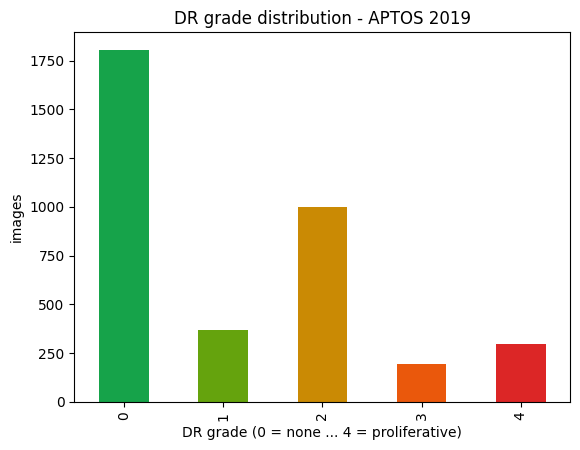

In [3]:
shutil.copy(train_csv, f'{PROJECT_PATH}/data/aptos/train.csv')
df = pd.read_csv(train_csv)
print(df['diagnosis'].value_counts().sort_index())

colors = ['#16a34a', '#65a30d', '#ca8a04', '#ea580c', '#dc2626']
ax = df['diagnosis'].value_counts().sort_index().plot(kind='bar', color=colors)
plt.title('DR grade distribution - APTOS 2019'); plt.xlabel('DR grade (0 = none ... 4 = proliferative)'); plt.ylabel('images')
plt.savefig(f'{PROJECT_PATH}/outputs/class_distribution.png', bbox_inches='tight'); plt.show()

## 3 · Test the preprocessing (resize + CLAHE) on one image

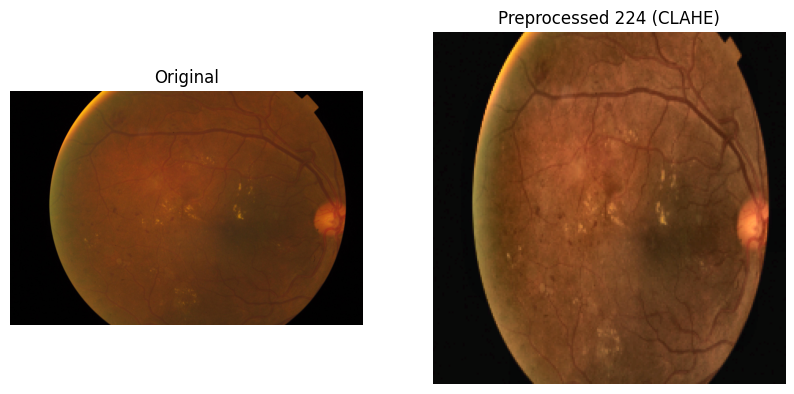

In [4]:
sid = df.iloc[0]['id_code']
orig = cv2.cvtColor(cv2.imread(f'{train_img_dir}/{sid}.png'), cv2.COLOR_BGR2RGB)
proc = prep_image(orig, CLS_SIZE)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(orig); ax[0].set_title('Original'); ax[0].axis('off')
ax[1].imshow(proc); ax[1].set_title('Preprocessed 224 (CLAHE)'); ax[1].axis('off')
plt.savefig(f'{PROJECT_PATH}/outputs/preprocessing_sample.png', bbox_inches='tight'); plt.show()

## 4 · Process ALL APTOS images → Drive (resumable, ~5-10 min)
If Colab disconnects: rerun cells 1 → this cell. Finished files are skipped.

In [5]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

OUT = f'{PROJECT_PATH}/data/processed'
def work(id_code):
    out = f'{OUT}/{id_code}.png'
    if os.path.exists(out):
        return None
    try:
        img = cv2.cvtColor(cv2.imread(f'{train_img_dir}/{id_code}.png'), cv2.COLOR_BGR2RGB)
        cv2.imwrite(out, cv2.cvtColor(prep_image(img, CLS_SIZE), cv2.COLOR_RGB2BGR))
    except Exception as e:
        return (id_code, str(e))

with ThreadPoolExecutor(4) as ex:
    errors = [r for r in tqdm(ex.map(work, df['id_code']), total=len(df)) if r]
print('errors:', errors)
print('processed files:', len(os.listdir(OUT)), '/', len(df))

  0%|          | 0/3662 [00:00<?, ?it/s]

errors: []
processed files: 3662 / 3662


## 5 · IDRiD part B (Disease Grading) → labels + preprocessed images
This is the **external test set** Person B uses to check generalisation.

In [10]:
idrid_zips = [p for p in glob.glob(f'{RAW}/*.zip') if 'grading' in p.lower()]
idrid_zip = idrid_zips[0] if idrid_zips else f'{RAW}/idrid.zip'

os.makedirs('/content/idrid_temp', exist_ok=True)
with zipfile.ZipFile(idrid_zip) as z:
    z.extractall('/content/idrid_temp')

# Filter paths to only target 'B. Disease Grading' folder
csv_files = glob.glob('/content/idrid_temp/**/B. Disease Grading/**/*.csv', recursive=True)
img_files = glob.glob('/content/idrid_temp/**/B. Disease Grading/**/*.jpg', recursive=True)
print(csv_files); print(len(img_files), 'jpg images (expect 516)')

parts = []
for f in csv_files:
    d = pd.read_csv(f); d.columns = [c.strip() for c in d.columns]
    parts.append(d[['Image name', 'Retinopathy grade']])
idrid = pd.concat(parts, ignore_index=True).dropna()
idrid.columns = ['id_code', 'diagnosis']
idrid['diagnosis'] = idrid['diagnosis'].astype(int)
print(len(idrid), 'labels (expect 516)'); print(idrid['diagnosis'].value_counts().sort_index())

paths = {os.path.splitext(os.path.basename(p))[0]: p for p in img_files}
for _, r in tqdm(idrid.iterrows(), total=len(idrid)):
    out = f'{PROJECT_PATH}/data/processed_idrid/{r.id_code}.png'
    if os.path.exists(out): continue
    img = cv2.cvtColor(cv2.imread(paths[r.id_code]), cv2.COLOR_BGR2RGB)
    cv2.imwrite(out, cv2.cvtColor(prep_image(img, CLS_SIZE), cv2.COLOR_RGB2BGR))
idrid.to_csv(f'{PROJECT_PATH}/data/idrid/labels.csv', index=False)
print('IDRiD processed:', len(os.listdir(f'{PROJECT_PATH}/data/processed_idrid')))

['/content/idrid_temp/IDRiD_dataset/B. Disease Grading/2. Groundtruths/b. IDRiD_Disease Grading_Testing Labels.csv', '/content/idrid_temp/IDRiD_dataset/B. Disease Grading/2. Groundtruths/a. IDRiD_Disease Grading_Training Labels.csv']
516 jpg images (expect 516)
516 labels (expect 516)
diagnosis
0    168
1     25
2    168
3     93
4     62
Name: count, dtype: int64


  0%|          | 0/516 [00:00<?, ?it/s]

IDRiD processed: 413


## 6 · Sample images for the app (one raw APTOS image per grade)

In [11]:
for g in range(5):
    r = df[df.diagnosis == g].iloc[0]
    img = cv2.imread(f'{train_img_dir}/{r.id_code}.png'); h, w = img.shape[:2]; s = 768 / max(h, w)
    img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    cv2.imwrite(f'{PROJECT_PATH}/app/samples/aptos_grade{g}.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 90])
print(os.listdir(f'{PROJECT_PATH}/app/samples'))

['aptos_grade0.jpg', 'aptos_grade1.jpg', 'aptos_grade2.jpg', 'aptos_grade3.jpg', 'aptos_grade4.jpg']


## 7 · One fast zip for Person B + README + final check

In [12]:
shutil.make_archive(f'{PROJECT_PATH}/data/processed_aptos', 'zip', f'{PROJECT_PATH}/data/processed')
open(f'{PROJECT_PATH}/data/README.txt', 'w').write("""DATA README (Person A)
- data/aptos/train.csv        APTOS labels (id_code, diagnosis 0-4)
- data/processed/             3662 APTOS images, 224x224, CLAHE, PNG, <id_code>.png
- data/processed_aptos.zip    same images as one zip -> copy to /content and unzip for fast training
- data/processed_idrid/       516 IDRiD images, same preprocessing
- data/idrid/labels.csv       IDRiD labels (id_code, diagnosis 0-4)
Images are uint8 0-255, NOT normalised. All preprocessing = dr_core.prep_image (app/dr_core.py).
""")
print('APTOS csv        :', os.path.exists(f'{PROJECT_PATH}/data/aptos/train.csv'))
print('APTOS processed  :', len(os.listdir(f'{PROJECT_PATH}/data/processed')), '/ 3662')
print('IDRiD processed  :', len(os.listdir(f'{PROJECT_PATH}/data/processed_idrid')), '/ 516')
print('IDRiD labels     :', os.path.exists(f'{PROJECT_PATH}/data/idrid/labels.csv'))
print('zip for Person B :', os.path.exists(f'{PROJECT_PATH}/data/processed_aptos.zip'))

APTOS csv        : True
APTOS processed  : 3662 / 3662
IDRiD processed  : 413 / 516
IDRiD labels     : True
zip for Person B : True


### ✅ Done with part 1 → message the team
> "Classification data is ready in Drive: `data/processed/` + `data/aptos/train.csv` (train), `data/processed_idrid/` + `data/idrid/labels.csv` (external test), zip: `data/processed_aptos.zip`. Details in `data/README.txt`."

**Next:** open notebook **02** (segmentation + localization). Do **not** delete `raw_upload` yet — notebook 02 needs the A and C zips.